In [30]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

In [31]:
url="https://raw.githubusercontent.com/aalanwar/Logical-Zonotope/refs/heads/main/README.md"
response = requests.get(url)
text=response.text
print(text[:500])


## Logical Zonotope and polynomial logical zonotopes: Set Representations for Binary Vectors

This repo cotains the code for our two papers: <br />

1- Polynomial Logical Zonotopes: A Set Representation for Reachability Analysis of Logical Systems <br />
Authors: Amr Alanwar, Frank J. Jiang, and Karl Henrik Johansson  <br />

1- Logical Zonotope: A Set Representation for the Formal Verification of Boolean Functions <br />
Authors: Amr Alanwar, Frank J. Jiang, Samy Amin and Karl Henrik Johansson


In [32]:
words = text.split()
print(len(words))
print(words[:20])

679
['##', 'Logical', 'Zonotope', 'and', 'polynomial', 'logical', 'zonotopes:', 'Set', 'Representations', 'for', 'Binary', 'Vectors', 'This', 'repo', 'cotains', 'the', 'code', 'for', 'our', 'two']


In [33]:
words_series = pd.Series(words)
word_counts = words_series.value_counts()
print(word_counts)

/>                40
<br               37
logical           34
the               22
of                18
                  ..
Functions},        1
year={2023},       1
volume={},         1
number={},         1
pages={60-66}}     1
Name: count, Length: 285, dtype: int64


In [34]:
import re

cleaned_words = [re.sub(r'[^a-zA-Z]', '', word).lower() for word in words]
cleaned_words = [word for word in cleaned_words if word != '']
print(cleaned_words[:20])

['logical', 'zonotope', 'and', 'polynomial', 'logical', 'zonotopes', 'set', 'representations', 'for', 'binary', 'vectors', 'this', 'repo', 'cotains', 'the', 'code', 'for', 'our', 'two', 'papers']


In [35]:
stopwords = ['the', 'a', 'an', 'be', 'of', 'and', 'to', 'in', 'is', 'for', 'with', 'on', 'at', 'by', 'it', 'as', 'are', 'was', 'this', 'that', 'from', 'or', 'we', 'our', 'br', 'z']


filtered_words = [word for word in cleaned_words if word not in stopwords]
print(len(filtered_words))

402


In [36]:
filtered_series = pd.Series(filtered_words)
filtered_counts = filtered_series.value_counts()

top10 = filtered_counts.head(10)
print(top10)

logical           40
zonotopes         17
polynomial        13
zonotope           8
two                7
set                6
reachability       6
analysis           6
between            6
representation     5
Name: count, dtype: int64


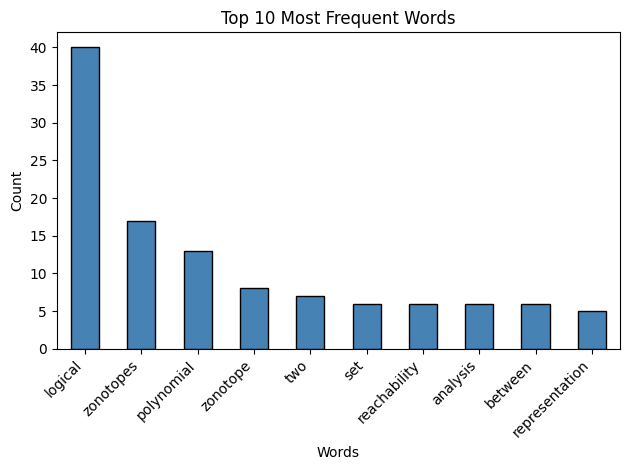

In [37]:
top10.plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('Top 10 Most Frequent Words')
plt.xlabel('Words')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('task_b_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

In [38]:

A = np.random.random((100, 20))
print(A.shape)

(100, 20)


In [39]:
v = np.random.normal(loc=2, scale=0.01, size=(20, 1))
print(v.shape)
print(v[:5])

(20, 1)
[[1.99574956]
 [2.01972035]
 [2.00437177]
 [1.9932224 ]
 [2.00448787]]


In [40]:
c = np.zeros(100)

for i in range(100):
    c[i] = np.sum(A[i, :] * v.flatten())

print(c.shape)
print(c[:5])

(100,)
[22.64974954 17.51874815 21.80342549 16.71834477 19.83724869]


In [41]:
mean_c = np.mean(c)
std_c = np.std(c)

print(f"Mean: {mean_c:.4f}")
print(f"Std Dev: {std_c:.4f}")

Mean: 19.8204
Std Dev: 2.5087


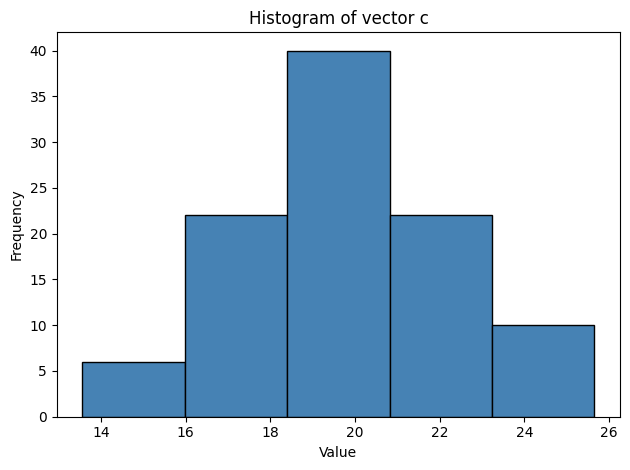

In [42]:
plt.hist(c, bins=5, color='steelblue', edgecolor='black')
plt.title('Histogram of vector c')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('task_c_histogram.png', dpi=150, bbox_inches='tight')
plt.show()

In [43]:
mu = 2
sigmas = [0.01, 0.1, 1]

datasets = []
for sigma in sigmas:
    A = np.random.normal(loc=mu, scale=sigma, size=(100, 2))
    datasets.append(A)

print(datasets[0].shape)
print(datasets[0][:3])

(100, 2)
[[1.9902767  2.01266054]
 [2.00258796 2.002409  ]
 [2.0164686  2.01016841]]


In [44]:
def learn_simple_linreg(A):
    x = A[:, 0]
    y = A[:, 1]
    
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    
    beta1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
    beta0 = y_mean - beta1 * x_mean
    
    return beta0, beta1


for i, A in enumerate(datasets):
    b0, b1 = learn_simple_linreg(A)
    print(f"sigma={sigmas[i]}: beta0={b0:.4f}, beta1={b1:.4f}")

sigma=0.01: beta0=2.1464, beta1=-0.0740
sigma=0.1: beta0=1.9568, beta1=0.0237
sigma=1: beta0=2.3970, beta1=-0.1664


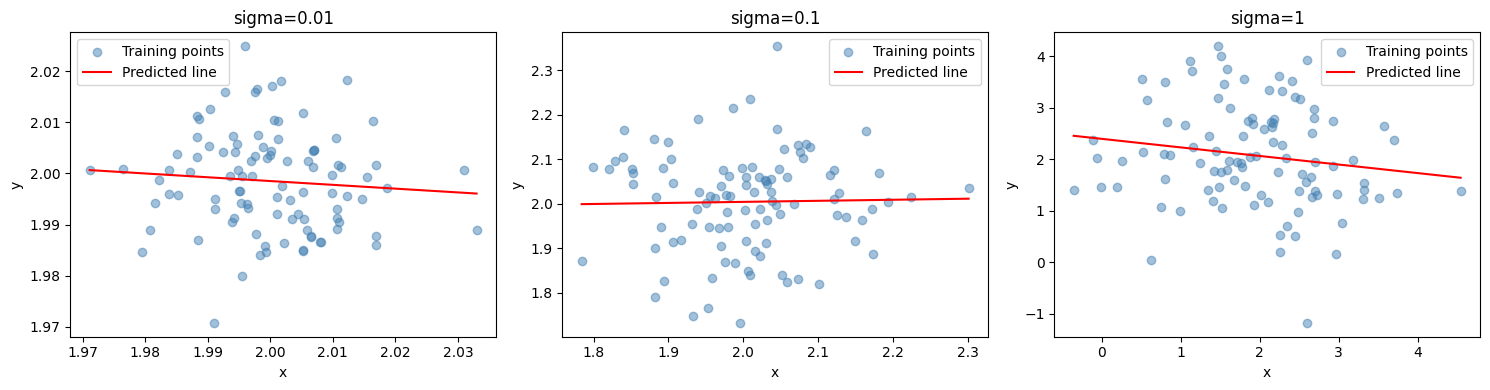

In [45]:
def predict_simple_linreg(x, beta0, beta1):
    y_hat = beta0 + beta1 * x
    return y_hat

%matplotlib inline

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, A in enumerate(datasets):
    x = A[:, 0]
    y = A[:, 1]
    
    b0, b1 = learn_simple_linreg(A)
    
    axes[i].scatter(x, y, color='steelblue', alpha=0.5, label='Training points')
    axes[i].plot(np.sort(x), predict_simple_linreg(np.sort(x), b0, b1), color='red', label='Predicted line')
    axes[i].set_title(f'sigma={sigmas[i]}')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].legend()

plt.tight_layout()
plt.savefig('q2_original_plot.png', dpi=150, bbox_inches='tight')
plt.show()

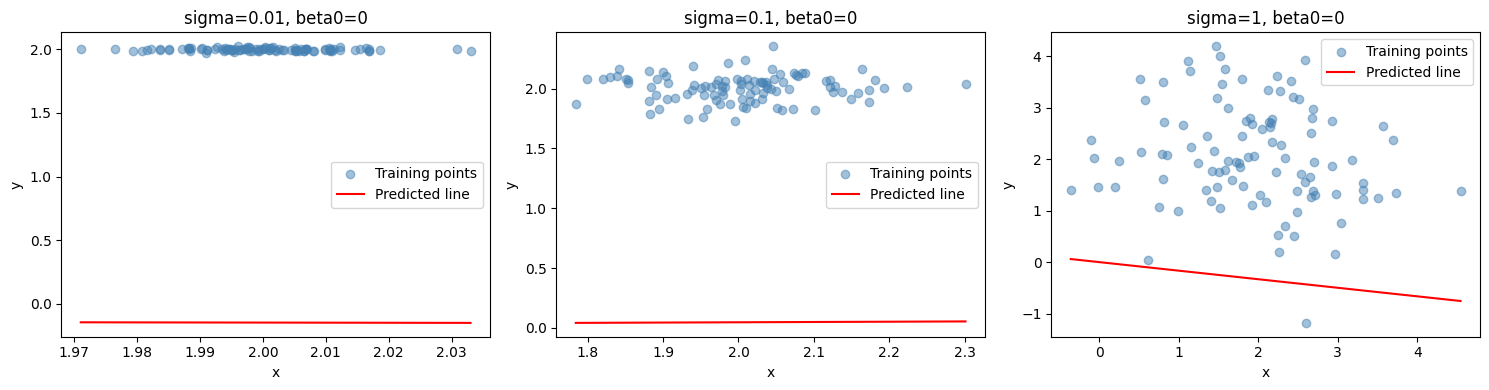

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, A in enumerate(datasets):
    x = A[:, 0]
    y = A[:, 1]
    
    b0, b1 = learn_simple_linreg(A)
    b0 = 0

    axes[i].scatter(x, y, color='steelblue', alpha=0.5, label='Training points')
    axes[i].plot(np.sort(x), predict_simple_linreg(np.sort(x), b0, b1), color='red', label='Predicted line')
    axes[i].set_title(f'sigma={sigmas[i]}, beta0=0')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].legend()

plt.tight_layout()
plt.savefig('q2_beta0_zero.png', dpi=150, bbox_inches='tight')
plt.show()

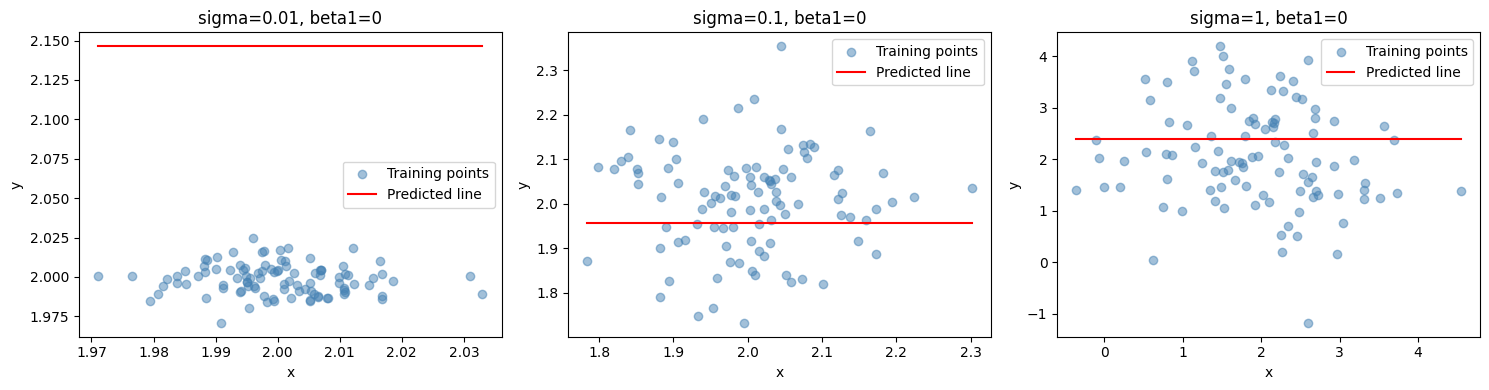

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, A in enumerate(datasets):
    x = A[:, 0]
    y = A[:, 1]
    
    b0, b1 = learn_simple_linreg(A)
    b1 = 0

    axes[i].scatter(x, y, color='steelblue', alpha=0.5, label='Training points')
    axes[i].plot(np.sort(x), predict_simple_linreg(np.sort(x), b0, b1), color='red', label='Predicted line')
    axes[i].set_title(f'sigma={sigmas[i]}, beta1=0')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].legend()

plt.tight_layout()
plt.savefig('q2_beta1_zero.png', dpi=150, bbox_inches='tight')
plt.show()

In [48]:
for i, A in enumerate(datasets):
    x = A[:, 0]
    y = A[:, 1]
    
    X = np.column_stack([np.ones(len(x)), x])
    result = np.linalg.lstsq(X, y, rcond=None)
    b0, b1 = result[0]
    print(f"sigma={sigmas[i]}: beta0={b0:.4f}, beta1={b1:.4f}")


sigma=0.01: beta0=2.1464, beta1=-0.0740
sigma=0.1: beta0=1.9568, beta1=0.0237
sigma=1: beta0=2.3970, beta1=-0.1664


In [49]:
from sklearn.linear_model import LinearRegression

for i, A in enumerate(datasets):
    x = A[:, 0].reshape(-1, 1)
    y = A[:, 1]
    
    model = LinearRegression()
    model.fit(x, y)
    
    print(f"sigma={sigmas[i]}: beta0={model.intercept_:.4f}, beta1={model.coef_[0]:.4f}")


sigma=0.01: beta0=2.1464, beta1=-0.0740
sigma=0.1: beta0=1.9568, beta1=0.0237
sigma=1: beta0=2.3970, beta1=-0.1664


In [50]:
import timeit

methods = {
    'Algorithm 1 (Manual)': lambda A: learn_simple_linreg(A),
    'numpy lstsq': lambda A: np.linalg.lstsq(
        np.column_stack([np.ones(len(A)), A[:, 0]]), A[:, 1], rcond=None
    ),
    'sklearn': lambda A: LinearRegression().fit(A[:, 0].reshape(-1, 1), A[:, 1])
}

print(f"{'Method':<25} {'sigma=0.01':>12} {'sigma=0.1':>12} {'sigma=1':>12}")
print("-" * 65)

for method_name, method_func in methods.items():
    times = []
    for A in datasets:
        t = timeit.timeit(lambda: method_func(A), number=1000)
        times.append(t / 1000 * 1000)  # convert to milliseconds
    print(f"{method_name:<25} {times[0]:>11.4f}ms {times[1]:>11.4f}ms {times[2]:>11.4f}ms")


Method                      sigma=0.01    sigma=0.1      sigma=1
-----------------------------------------------------------------
Algorithm 1 (Manual)           0.0340ms      0.0282ms      0.0304ms
numpy lstsq                    0.0270ms      0.0270ms      0.0313ms
sklearn                        0.5443ms      0.5457ms      0.5827ms


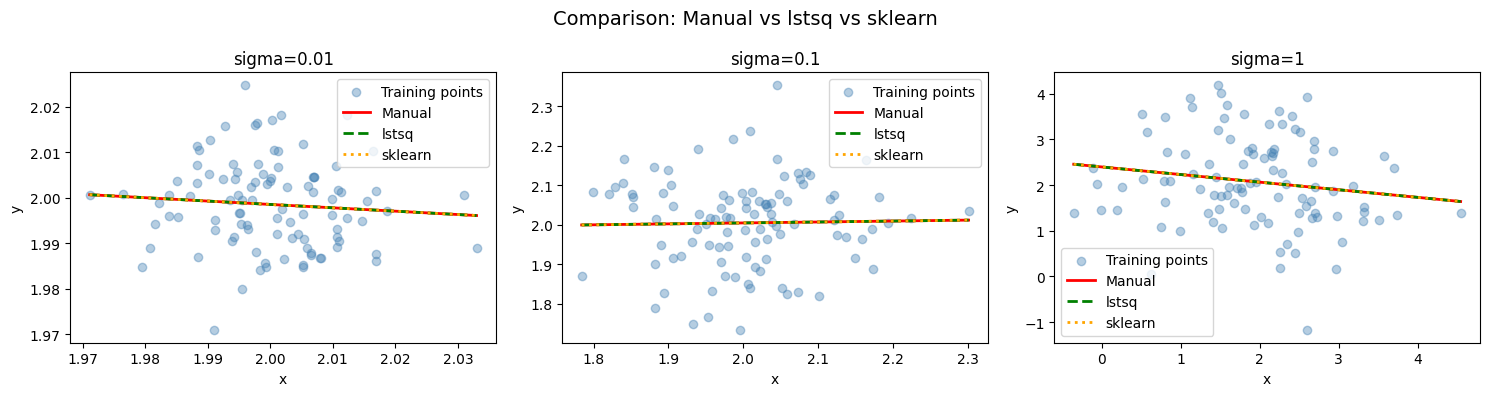

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, A in enumerate(datasets):
    x = A[:, 0]
    y = A[:, 1]
    x_sorted = np.sort(x)

    b0_manual, b1_manual = learn_simple_linreg(A)
    
    X = np.column_stack([np.ones(len(x)), x])
    b0_lstsq, b1_lstsq = np.linalg.lstsq(X, y, rcond=None)[0]
    
    model = LinearRegression()
    model.fit(x.reshape(-1, 1), y)
    b0_sk, b1_sk = model.intercept_, model.coef_[0]

    axes[i].scatter(x, y, color='steelblue', alpha=0.4, label='Training points', zorder=1)
    axes[i].plot(x_sorted, b0_manual + b1_manual * x_sorted, color='red', linewidth=2, label='Manual')
    axes[i].plot(x_sorted, b0_lstsq + b1_lstsq * x_sorted, color='green', linewidth=2, linestyle='--', label='lstsq')
    axes[i].plot(x_sorted, b0_sk + b1_sk * x_sorted, color='orange', linewidth=2, linestyle=':', label='sklearn')
    axes[i].set_title(f'sigma={sigmas[i]}')
    axes[i].set_xlabel('x')
    axes[i].set_ylabel('y')
    axes[i].legend()

plt.suptitle('Comparison: Manual vs lstsq vs sklearn', fontsize=14)
plt.tight_layout()
plt.savefig('q2_comparison_plot.png', dpi=150, bbox_inches='tight')
plt.show()